# Deep Neural Network:

<a name='1'></a>
## 1 - Packages

In [1]:
# Package imports
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
from dnn_app_utils_v3 import *

np.random.seed(1)

<a name='2'></a>
# 2 - Load the Dataset and Normalization

In [2]:
# Loading the data
weather_2021 = pd.read_csv("Data/ninja_weather_2021.csv", comment="#")
weather_2022 = pd.read_csv("Data/ninja_weather_2022.csv", comment ="#") 
weather_2023 = pd.read_csv("Data/ninja_weather_2023.csv", comment="#")
weather_2024 = pd.read_csv("Data/ninja_weather_2024.csv", comment="#")
weather_2025 = pd.read_csv("Data/ninja_weather_2025.csv", comment="#")
 
pv_2021 = pd.read_csv("Data/ninja_pv_2021.csv", comment="#")
pv_2022 = pd.read_csv("Data/ninja_pv_2022.csv", comment="#")
pv_2023 = pd.read_csv("Data/ninja_pv_2023.csv", comment="#")
pv_2024 = pd.read_csv("Data/ninja_pv_2024.csv", comment="#")
pv_2025 = pd.read_csv("Data/ninja_pv_2025.csv", comment="#")

In [3]:
#Merging the weather and pv data
weather = pd.concat([weather_2021, weather_2022, weather_2023, weather_2024, weather_2025], ignore_index=True)
pv = pd.concat([pv_2021, pv_2022, pv_2023, pv_2024, pv_2025], ignore_index=True)

data = pd.merge(weather, pv, on="time")

data["time"] = pd.to_datetime(data["time"])    # timestamps as datetime
data = data.set_index("time")                  # set time as the index
                                                
 
time = data.index                              # keep the timestamps
input_data = data.values                       # .values converts a pandas dataframe to a numpy array

In [4]:
split = int(0.8 * input_data.shape[0])   # 80/20 split
 
train_set_x_orig = input_data[:split, 0:8]
test_set_x_orig = input_data[split:, 0:8]
train_set_y_orig = input_data[:split, -1:]
test_set_y_orig = input_data[split:, -1:]

<a name='5'></a>
## 5 - L-layer Neural Network


In [5]:
def L_layer_model(X, Y, layers_dims, learning_rate=0.0075, num_iterations=3000, print_cost=False):
 
    costs = []                                          
 
    # Parameters initialization
    parameters = initialize_parameters_deep(layers_dims)
 
    # Loop (gradient descent)
    for i in range(0, num_iterations):
 
        # Forward propagation:
        AL, caches = L_model_forward(X, parameters)
 
        # Compute cost
        cost = compute_cost(AL, Y)
 
        # Backward propagation
        grads = L_model_backward(AL, Y, caches)
 
        # Update parameters
        parameters = update_parameters(parameters, grads, learning_rate)
 
        # Print the cost every 100 iterations
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print("Cost after iteration %i: %f" % (i, cost))
 
    return parameters, costs

In [6]:
def model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, layers_dims, num_iterations=3000, learning_rate=0.0075, print_cost=False):
 
    parameters, costs = L_layer_model(train_set_x_normalized, train_set_y_normalized, layers_dims, learning_rate, num_iterations, print_cost)
 
    Y_prediction_test, caches = L_model_forward(test_set_x_normalized, parameters)
    Y_prediction_train, caches = L_model_forward(train_set_x_normalized, parameters)
 
    # Print train/test Errors
    if print_cost:
        print("train accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_train - train_set_y_normalized)) * 100))
        print("test accuracy: {} %".format(100 - np.mean(np.abs(Y_prediction_test - test_set_y_normalized)) * 100))
 
    d = {"costs": costs,
         "Y_prediction_test": Y_prediction_test,
         "Y_prediction_train": Y_prediction_train,
         "parameters": parameters,
         "layers_dims": layers_dims,
         "learning_rate": learning_rate,
         "num_iterations": num_iterations}
    return d

In [7]:
def evaluate(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    r2 = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return mae, rmse, r2

In [8]:
# ---------- cross-validation: rolling window with a gap (only on the training set) ----------
n_splits = 5
gap = 24                 # 24 h gap between training and validation
val_size = 2190          # ~ 1 quarter of validation data per fold
train_window = len(train_set_x_orig) - n_splits * val_size - gap   
 
tscv = TimeSeriesSplit(n_splits=n_splits, max_train_size=train_window, gap=gap, test_size=val_size)
 
def cross_validate(hidden_layers, num_iterations, learning_rate, print_folds=False):
 
    scores = []
 
    for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
        x_train = train_set_x_orig[train_idx]
        x_val = train_set_x_orig[val_idx]
        y_train = train_set_y_orig[train_idx]
        y_val = train_set_y_orig[val_idx]
 
        # normalization: fit only on the training fold, then apply to the validation fold
        scaler_x = MinMaxScaler(feature_range=(0,1))
        scaler_y = MinMaxScaler(feature_range=(0,1))
        x_train_normalized = scaler_x.fit_transform(x_train)
        x_val_normalized = scaler_x.transform(x_val)
        y_train_normalized = scaler_y.fit_transform(y_train)
        y_val_normalized = scaler_y.transform(y_val)
 
        # transpose: features in the rows, samples in the columns
        x_train_normalized = x_train_normalized.T
        x_val_normalized = x_val_normalized.T
        y_train_normalized = y_train_normalized.T
        y_val_normalized = y_val_normalized.T
 
        # layer sizes: input layer, hidden layers, output layer
        layers_dims = [x_train_normalized.shape[0]] + hidden_layers + [1]
 
        # train on the training fold, predict the validation fold
        fold_model = model(x_train_normalized, y_train_normalized, x_val_normalized, y_val_normalized, layers_dims, num_iterations, learning_rate)
 
        # reverse normalization (back to kW) and evaluation
        y_pred_kw = scaler_y.inverse_transform(fold_model["Y_prediction_test"].T)
        scores.append(evaluate(y_val, y_pred_kw))
 
        if print_folds:
            print("fold", fold + 1, "| training:", time[train_idx[0]], "to", time[train_idx[-1]], "| validation:", time[val_idx[0]], "to", time[val_idx[-1]])
 
    return np.array(scores)

In [9]:
# ---------- hyperparameter selection with the cross-validation ----------
hidden_layers_list = [[]]     # sizes of the hidden layers. [] = logistic regression (no hidden layers)
learning_rates = [0.85, 2.0, 5.0]
iterations_list = [1000, 3000, 5000]
 
best_rmse = np.inf
 
for hidden_layers in hidden_layers_list:
    for learning_rate in learning_rates:
        for num_iterations in iterations_list:
            scores = cross_validate(hidden_layers, num_iterations, learning_rate)
            mean_scores = scores.mean(axis=0)      # mean MAE, RMSE, R2 over the folds
            print("hidden layers:", hidden_layers, "| learning rate:", learning_rate, "| iterations:", num_iterations, "| mean MAE, RMSE, R2:", mean_scores)
 
            if mean_scores[1] < best_rmse:         # the mean RMSE decides
                best_rmse = mean_scores[1]
                best_hidden_layers = hidden_layers
                best_learning_rate = learning_rate
                best_num_iterations = num_iterations
 
print("best setting: hidden layers =", best_hidden_layers, ", learning rate =", best_learning_rate, ", iterations =", best_num_iterations, ", mean RMSE =", best_rmse)
 
# scores per fold for the best setting
scores = cross_validate(best_hidden_layers, best_num_iterations, best_learning_rate, print_folds=True)
print("MAE, RMSE, R2 per fold:")
print(scores)
print("mean:", scores.mean(axis=0))
print("std:", scores.std(axis=0))

hidden layers: [] | learning rate: 0.85 | iterations: 1000 | mean MAE, RMSE, R2: [35.04349939 62.86169001  0.76407841]
hidden layers: [] | learning rate: 0.85 | iterations: 3000 | mean MAE, RMSE, R2: [34.82069078 61.89682543  0.77291231]
hidden layers: [] | learning rate: 0.85 | iterations: 5000 | mean MAE, RMSE, R2: [34.68340662 61.28042194  0.77531847]
hidden layers: [] | learning rate: 2.0 | iterations: 1000 | mean MAE, RMSE, R2: [34.87827585 62.19579957  0.77139475]
hidden layers: [] | learning rate: 2.0 | iterations: 3000 | mean MAE, RMSE, R2: [34.606494   60.99286312  0.77620162]
hidden layers: [] | learning rate: 2.0 | iterations: 5000 | mean MAE, RMSE, R2: [34.51477718 60.79330203  0.77659465]
hidden layers: [] | learning rate: 5.0 | iterations: 1000 | mean MAE, RMSE, R2: [34.64577681 61.12963413  0.77580687]
hidden layers: [] | learning rate: 5.0 | iterations: 3000 | mean MAE, RMSE, R2: [34.45700174 60.75857505  0.77649421]
hidden layers: [] | learning rate: 5.0 | iterations: 

In [10]:
# ---------- final model: whole training set, evaluation on the test set ----------
scaler_x = MinMaxScaler(feature_range=(0,1))
scaler_y = MinMaxScaler(feature_range=(0,1))
train_set_x_normalized = scaler_x.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler_x.transform(test_set_x_orig)
train_set_y_normalized = scaler_y.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler_y.transform(test_set_y_orig)
 
train_set_x_normalized = train_set_x_normalized.T     
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T
 
layers_dims = [train_set_x_normalized.shape[0]] + best_hidden_layers + [1]
 
deep_nn_model = model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, layers_dims, best_num_iterations, best_learning_rate, print_cost=True)

Cost after iteration 0: 0.779670
Cost after iteration 100: 0.224001
Cost after iteration 200: 0.222121
Cost after iteration 300: 0.221635
Cost after iteration 400: 0.221398
Cost after iteration 500: 0.221253
Cost after iteration 600: 0.221158
Cost after iteration 700: 0.221094
Cost after iteration 800: 0.221049
Cost after iteration 900: 0.221016
Cost after iteration 1000: 0.220991
Cost after iteration 1100: 0.220972
Cost after iteration 1200: 0.220957
Cost after iteration 1300: 0.220944
Cost after iteration 1400: 0.220933
Cost after iteration 1500: 0.220923
Cost after iteration 1600: 0.220914
Cost after iteration 1700: 0.220905
Cost after iteration 1800: 0.220897
Cost after iteration 1900: 0.220890
Cost after iteration 2000: 0.220883
Cost after iteration 2100: 0.220876
Cost after iteration 2200: 0.220870
Cost after iteration 2300: 0.220864
Cost after iteration 2400: 0.220858
Cost after iteration 2500: 0.220852
Cost after iteration 2600: 0.220847
Cost after iteration 2700: 0.220841
Cost

test MAE, RMSE, R2: (np.float64(34.509238984916934), np.float64(57.735141662397076), np.float64(0.9126535175271934))


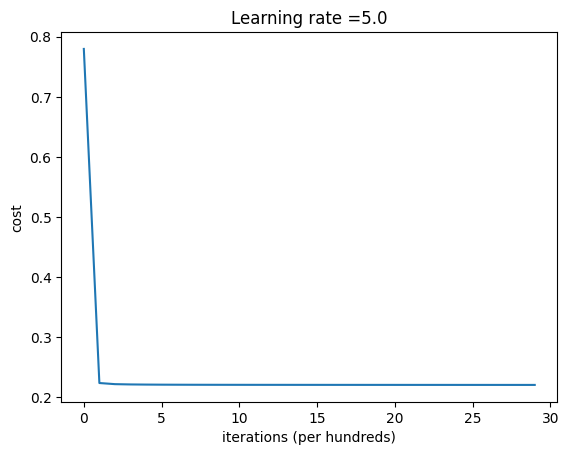

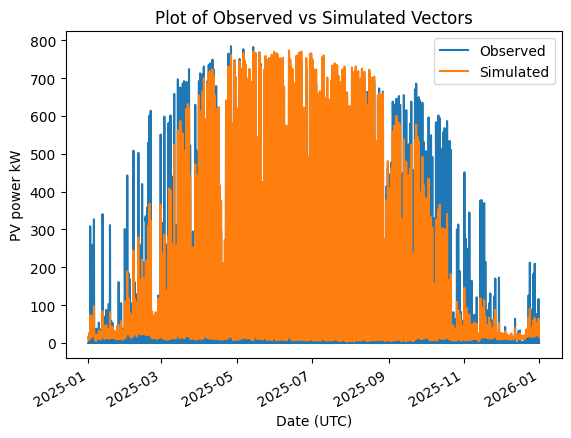

In [11]:
#Reverse normalization
Y_prediction_test_real_scale = scaler_y.inverse_transform(deep_nn_model["Y_prediction_test"].T)
print("test MAE, RMSE, R2:", evaluate(test_set_y_orig, Y_prediction_test_real_scale))
 
# Plot learning curve (with costs)
costs = np.squeeze(deep_nn_model['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)')
plt.title("Learning rate =" + str(deep_nn_model["learning_rate"]))
plt.show()
 
# Results analysis
x = time[split:]                               # datetime index of the test period
y1 = test_set_y_orig
y2 = Y_prediction_test_real_scale
 
plt.plot(x, y1, label='Observed')
plt.plot(x, y2, label='Simulated')
plt.title('Plot of Observed vs Simulated Vectors')
plt.xlabel('Date (UTC)')
plt.ylabel('PV power kW')
plt.ylim()
plt.legend()
plt.gcf().autofmt_xdate()                    # tilt the date labels
plt.show()

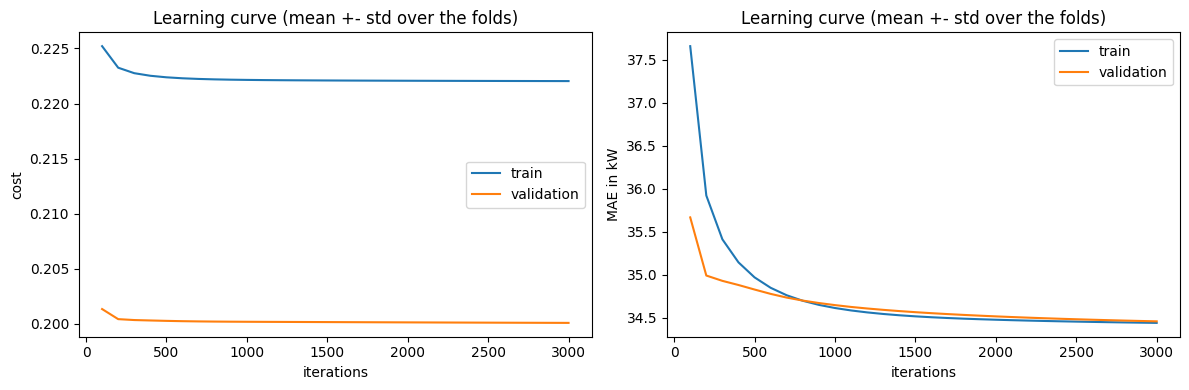

In [ ]:

# ---------- learning curves: train vs validation (mean over the CV folds) ----------
total_iterations = 5000    # longer than the training above, to see if the validation error starts to rise
step = 100                 # evaluate every 100 iterations
n_points = total_iterations // step
 
train_cost = np.zeros((n_splits, n_points))
val_cost = np.zeros((n_splits, n_points))
train_mae = np.zeros((n_splits, n_points))
val_mae = np.zeros((n_splits, n_points))
 
for fold, (train_idx, val_idx) in enumerate(tscv.split(train_set_x_orig)):
    x_train = train_set_x_orig[train_idx]
    x_val = train_set_x_orig[val_idx]
    y_train = train_set_y_orig[train_idx]
    y_val = train_set_y_orig[val_idx]
 
    # same normalization as in the cross-validation
    scaler_x = MinMaxScaler(feature_range=(0,1))
    scaler_y = MinMaxScaler(feature_range=(0,1))
    x_train_normalized = scaler_x.fit_transform(x_train).T
    x_val_normalized = scaler_x.transform(x_val).T
    y_train_normalized = scaler_y.fit_transform(y_train).T
    y_val_normalized = scaler_y.transform(y_val).T
 
    y_range = np.max(y_train) - np.min(y_train)    # to convert the normalized error back to kW
 
    layers_dims = [x_train_normalized.shape[0]] + best_hidden_layers + [1]
    parameters = initialize_parameters_deep(layers_dims)
 
    for k in range(n_points):
        # continue the training for another 100 iterations (same steps as in L_layer_model)
        for i in range(step):
            AL, caches = L_model_forward(x_train_normalized, parameters)
            grads = L_model_backward(AL, y_train_normalized, caches)
            parameters = update_parameters(parameters, grads, best_learning_rate)
 
        AL_train, caches = L_model_forward(x_train_normalized, parameters)
        AL_val, caches = L_model_forward(x_val_normalized, parameters)
 
        train_cost[fold, k] = compute_cost(AL_train, y_train_normalized)
        val_cost[fold, k] = compute_cost(AL_val, y_val_normalized)
 
        train_mae[fold, k] = np.mean(np.abs(AL_train - y_train_normalized)) * y_range
        val_mae[fold, k] = np.mean(np.abs(AL_val - y_val_normalized)) * y_range
 
iterations = np.arange(step, total_iterations + 1, step)
 
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
 
for i, (train_curve, val_curve, label) in enumerate([(train_cost, val_cost, 'cost'), (train_mae, val_mae, 'MAE in kW')]):
    ax[i].plot(iterations, train_curve.mean(axis=0), label='train')
    ax[i].plot(iterations, val_curve.mean(axis=0), label='validation')
    ax[i].set_xlabel('iterations')
    ax[i].set_ylabel(label)
    ax[i].set_title('Learning curve (mean +- std over the folds)')
    ax[i].legend()
 
plt.tight_layout()
plt.show()